In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [10]:
# znajdź pustą linię oddzielającą tabele
path = 'open-meteo.csv'
with open(path) as f:
    for i, line in enumerate(f):
        if not line.strip():
            break

locations = pd.read_csv(path, nrows=i - 1)
temps = pd.read_csv(path, skiprows=i + 1)
temps = temps.rename(columns={'temperature_2m (°C)': 'temperature'})

cities = {0: 'Warszawa', 1: 'Krakow', 2: 'Gdansk', 3: 'Wroclaw', 4: 'Poznan'}
temps['city'] = temps['location_id'].map(cities)

wide = temps.pivot(index='time', columns='city', values='temperature')


temps = temps.merge(locations, on='location_id', how='left')
# print(locations.head())
# print(temps.head())
print(wide.head())

city              Gdansk  Krakow  Poznan  Warszawa  Wroclaw
time                                                       
1940-01-01T00:00     NaN     NaN     NaN       NaN      NaN
1940-01-01T01:00     NaN     NaN     NaN       NaN      NaN
1940-01-01T02:00    -4.5    -4.9    -4.9      -7.3     -3.6
1940-01-01T03:00    -4.8    -4.9    -4.5      -6.8     -3.6
1940-01-01T04:00    -4.5    -4.8    -4.4      -6.6     -3.7


In [11]:
city = 'Wroclaw'

# tworze nowy DataFrame z danymi dla wybranego miasta, zawierający kolumny 'temperature' i 'time'
# aby było łatwiej filtrować i analizować dane czasowe, konwertuję kolumnę 'time' na typ datetime

city_data = pd.DataFrame({'temperature': wide[city], 'time': wide.index})
print(city_data['time'].dtype)


city_data['time'] = pd.to_datetime(city_data['time']) # konwersja kolumny 'time' na typ datetime 
# !!! Bardzo ważne, w szeregach czasowych zasze konwertujemy stringi z czasem na typ datetime, 
# aby móc je filtrować i analizować w czasie. 

# city_data = city_data[city_data['time'] > '2024-01-01 12:00:00'] # filtrowanie danych dla godziny 12

city_data.set_index('time', inplace=True) # ustawienie kolumny 'time' jako indeksu DataFrame, przydatne przy wizualizacji i analizie danych czasowych
print(city_data.head())


str
                     temperature
time                            
1940-01-01 00:00:00          NaN
1940-01-01 01:00:00          NaN
1940-01-01 02:00:00         -3.6
1940-01-01 03:00:00         -3.6
1940-01-01 04:00:00         -3.7


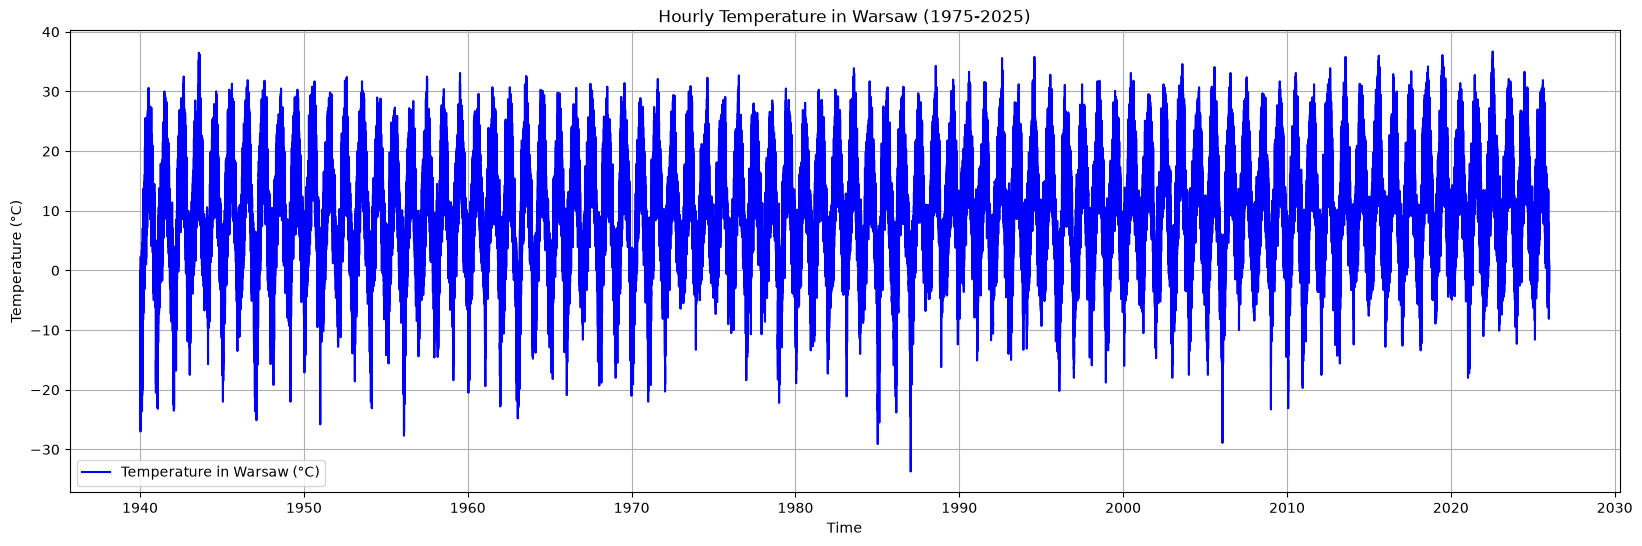

In [12]:
figure = plt.figure(figsize=(20, 6))
plt.plot(city_data.index, city_data['temperature'], color='blue', label='Temperature in Warsaw (°C)')
plt.xlabel('Time')
plt.ylabel('Temperature (°C)')
plt.title('Hourly Temperature in Warsaw (1975-2025)')
plt.legend()
plt.grid()
plt.show()

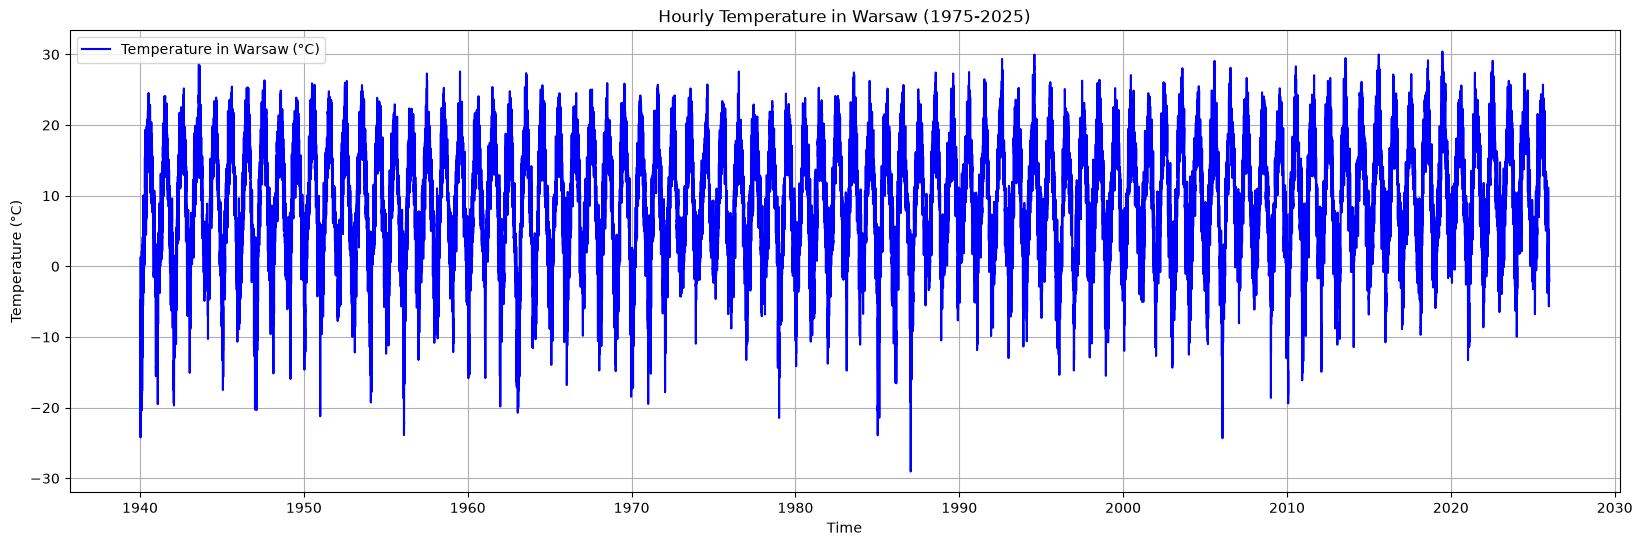

In [13]:
figure = plt.figure(figsize=(20, 6))
plt.plot(city_data.index, city_data['temperature'].rolling(window=24).mean(), color='blue', label='Temperature in Warsaw (°C)')
plt.xlabel('Time')
plt.ylabel('Temperature (°C)')
plt.title('Hourly Temperature in Warsaw (1975-2025)')
plt.legend()
plt.grid()
plt.show()

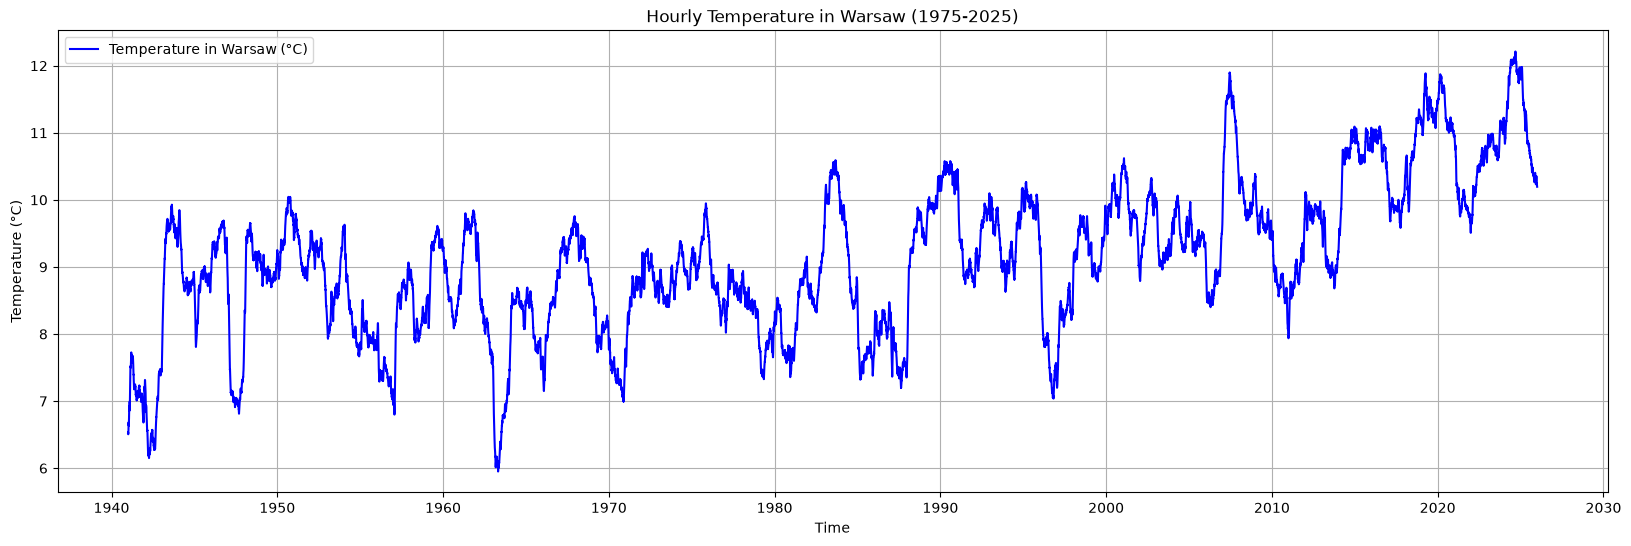

In [14]:
figure = plt.figure(figsize=(20, 6))
plt.plot(city_data.index, city_data['temperature'].rolling(window=24*365).mean(), color='blue', label='Temperature in Warsaw (°C)')
plt.xlabel('Time')
plt.ylabel('Temperature (°C)')
plt.title('Hourly Temperature in Warsaw (1975-2025)')
plt.legend()
plt.grid()
plt.show()